# LSTM 演示：化学动力学中的连续一级反应

## 一、演示说明

### 1. 化学反应背景

本演示研究由两步组成、每一步都是一级的**连续反应**（consecutive first-order reaction）：

```
A --k1--> B --k2--> C
```

- **A** 是反应物，按一级反应规律不断消耗；
- **B** 是中间产物，由 A 生成、同时又继续分解为 C，因此其浓度会**先升高、后降低**，出现一个峰值；
- **C** 是最终产物，浓度单调增加。

设 $A_0$ 为 A 的初始浓度，$k_1$、$k_2$ 为两步反应的速率常数，则速率方程为

$$
\frac{\mathrm{d}C_A}{\mathrm{d}t} = -k_1 C_A,\qquad
\frac{\mathrm{d}C_B}{\mathrm{d}t} = k_1 C_A - k_2 C_B,\qquad
\frac{\mathrm{d}C_C}{\mathrm{d}t} = k_2 C_B
$$

解这个微分方程组，可得**解析解**（本演示用它来“造”数据）：

$$
C_A = A_0\,e^{-k_1 t},\qquad
C_B = \frac{A_0 k_1}{k_2-k_1}\left(e^{-k_1 t}-e^{-k_2 t}\right),\qquad
C_C = A_0 - C_A - C_B
$$

注意 $C_A + C_B + C_C = A_0$ 恒成立——这是物料守恒，也可以作为检查数据是否正确的一个依据。

### 2. 任务定义：用历史浓度预测下一时刻浓度

把每个时刻的三种浓度组成一个向量 $[C_A, C_B, C_C]$，整条反应过程就是一条**时间序列**：

- **输入**：过去 20 个时间点的浓度序列，形状为 $(20, 3)$；
- **输出**：下一个时间点的三种浓度，形状为 $(3,)$。

这属于**多变量时间序列的回归（预测）任务**，正好适合用 LSTM（长短期记忆网络）来学习。

### 3. 为什么用 LSTM？

- 化学动力学数据本身就是“时间 → 浓度”的序列，相邻时刻强相关，LSTM 的循环结构和门控机制天生适合处理这类数据；
- 在真实体系中，反应常常是多步耦合、没有解析解，或者只能测得带噪声的数据；此时可以用 LSTM 直接从历史数据中学习演化规律；
- 本演示特意选择**有解析解**的简单体系，目的是：我们可以精确判断模型有没有学对（把预测值与真实值逐点比较）。

### 4. 数据划分

为了更接近真实场景，本演示模拟 **6 次独立实验**（初始浓度和速率常数略有不同），每次实验采样 201 个时间点：

- 第 1~5 次实验用于**训练**；
- 第 6 次实验（下标 2，即第 3 次）用于**测试**，训练时完全没见过。

**按整条实验轨迹划分**训练/测试集，而不是随机打乱所有窗口——否则同一条轨迹相邻的窗口会同时出现在训练集和测试集，造成信息泄漏，测试结果会虚高。

### 5. 评估方法

1. **RMSE（均方根误差）**：把预测浓度反标准化回真实单位后，与真实浓度比较，单位为 mol/L；
2. **持久化基线（persistence baseline）**：简单地把“当前时刻浓度”当作“下一时刻浓度”。如果 LSTM 的误差明显小于这个基线，说明它确实学到了变化趋势，而不只是简单地复制上一步。

### 6. 演示流程

| 步骤 | 内容 |
|---|---|
| 0 | 导入库、固定随机种子 |
| 1 | 用解析解生成 6 次带噪声的模拟实验 |
| 2 | 滑动窗口切分训练/测试样本，并做标准化 |
| 3 | 定义 LSTM 回归模型 |
| 4 | 训练（MSE 损失 + Adam + 梯度裁剪） |
| 5 | 在未参与训练的轨迹上评估，并与基线对比 |
| 6 | 画图对比真实值与预测值、观察损失曲线 |

### 7. 依赖包与学习目标

依赖：`numpy`、`torch`、`matplotlib`。

学习目标：

- 理解连续一级反应的浓度曲线与解析解；
- 会把一条时间序列切成“输入窗口 → 下一时刻”的监督学习样本；
- 掌握用 `nn.LSTM` 做回归的基本流程（标准化、DataLoader、训练循环、反标准化、评估）；
- 理解“基线对比”和“按轨迹划分数据”这两个实验设计要点。

In [1]:
# ===== 0. 导入依赖、固定随机种子 =====
import os

# Windows 下 numpy 与 torch 可能各自链接 OpenMP，设置该变量可避免“重复加载库”报错（仅对本进程生效）
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import numpy as np                     # 数值计算：数组、指数、随机噪声
import torch                           # 深度学习框架
import torch.nn as nn                  # 网络层：LSTM、Linear、MSELoss
from torch.utils.data import TensorDataset, DataLoader   # 封装小批量训练数据
import matplotlib.pyplot as plt        # 绘图

# 固定随机种子：让噪声、参数初始化、批顺序每次运行都一致，结果可复现
np.random.seed(42)
torch.manual_seed(42)

# 让图中的中文正常显示（Windows 常用 SimHei / 微软雅黑）
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False   # 坐标轴负号正常显示

print("numpy:", np.__version__, "| torch:", torch.__version__)

numpy: 2.2.6 | torch: 2.5.1+cu124


## 1. 生成模拟实验数据

### 代码思路

1. 设定时间轴 `t`：从 0 到 20，采样间隔 `dt = 0.1`，共 201 个时刻；
2. 写一个函数 `simulate_run(A0, k1, k2)`：
   - 分别用三条解析解计算 `C_A`、`C_B`、`C_C`；
   - 用 `np.stack` 把三者按列拼成形状为 `(201, 3)` 的矩阵，每一行 = 某一时刻的 `[A, B, C]`；
   - 叠加高斯噪声模拟测量误差（真实实验都有噪声）；
   - 用 `np.clip(..., 0, None)` 把偶然出现的负浓度截断为 0。
3. 循环 6 次，每次给不同的 $A_0$、$k_1$、$k_2$，得到 6 条轨迹(不同实验条件下的独立实验)。

> 关键点：`k2 < k1` 才能看到 B 的“先升后降”峰；若 $k_2$ 远大于 $k_1$，B 几乎一生成就立刻变成 C，峰会很矮。

In [2]:
# ===== 1. 用解析解模拟 6 次“实验” =====
dt = 0.1                                  # 采样间隔（时间步长）
t = np.arange(0, 20 + dt / 2, dt)         # 时间轴：0, 0.1, ..., 20，共 201 个点
noise_sigma = 0.003                       # 测量噪声的标准差（模拟仪器误差）
n_runs = 6                                # 独立实验次数：前 5 次训练，第 6 次测试


def simulate_run(A0, k1, k2):
    '''按连续一级反应的解析解生成一条浓度轨迹，并叠加测量噪声。

    参数:
        A0 : A 的初始浓度
        k1 : 第一步 A -> B 的速率常数
        k2 : 第二步 B -> C 的速率常数
    返回:
        shape=(201, 3) 的数组，每一行是某时刻的 [C_A, C_B, C_C]
    '''
    C_A = A0 * np.exp(-k1 * t)                                            # A：单调衰减
    C_B = A0 * k1 / (k2 - k1) * (np.exp(-k1 * t) - np.exp(-k2 * t))       # B：先升后降
    C_C = A0 - C_A - C_B                                                  # C：由物料守恒得到

    clean = np.stack([C_A, C_B, C_C], axis=1)          # (201, 3)：每行一个时刻的三个浓度
    noisy = clean + np.random.normal(0, noise_sigma, clean.shape)   # 叠加高斯噪声
    return np.clip(noisy, 0, None)                     # 浓度不能为负，负值截断为 0


# 6 次实验：A0 从 0.80 递增到 1.20，k1 从 0.70 到 0.90，k2 从 0.20 到 0.30
# 参数化 r的线性函数只是生成数据的便利写法；更“真实”的做法是让k在范围内随机取值，而不是与A完全正相关。
runs = []
for r in range(n_runs):
    runs.append(simulate_run(A0=0.8 + 0.08 * r,
                             k1=0.7 + 0.04 * r,
                             k2=0.20 + 0.02 * r))

print("=" * 62)
print("数据集：连续一级反应 A -> B -> C")
print(f"实验次数: {n_runs}，每次 {len(t)} 个时间点，采样间隔 dt={dt}")
print(f"单次实验数据形状: {runs[0].shape}  (行=时间点，列=[A, B, C])")
print("各次实验的 k1 ≈ 0.70~0.90，k2 ≈ 0.20~0.30")
print("=" * 62)

数据集：连续一级反应 A -> B -> C
实验次数: 6，每次 201 个时间点，采样间隔 dt=0.1
单次实验数据形状: (201, 3)  (行=时间点，列=[A, B, C])
各次实验的 k1 ≈ 0.70~0.90，k2 ≈ 0.20~0.30


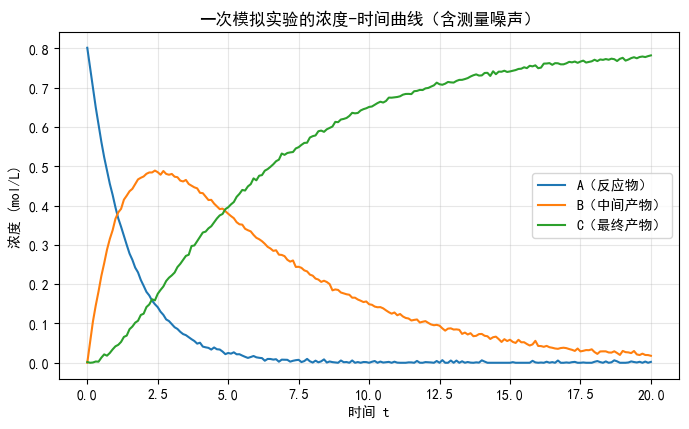

t= 0.0: A=0.8015  B=0.0000  C=0.0019
t= 2.0: A=0.1958  B=0.4740  C=0.1248
t= 2.5: A=0.1415  B=0.4849  C=0.1754
t= 5.0: A=0.0249  B=0.3792  C=0.3956
t=10.0: A=0.0000  B=0.1489  C=0.6510
t=20.0: A=0.0023  B=0.0177  C=0.7821


In [3]:
# ===== 1.1 观察一次实验的浓度曲线 =====
run0 = runs[0]   # 取第 1 次实验画图

plt.figure(figsize=(8, 4.5))
plt.plot(t, run0[:, 0], label="A（反应物）")
plt.plot(t, run0[:, 1], label="B（中间产物）")
plt.plot(t, run0[:, 2], label="C（最终产物）")
plt.xlabel("时间 t")
plt.ylabel("浓度 (mol/L)")
plt.title("一次模拟实验的浓度-时间曲线（含测量噪声）")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 打印几个关键时间点的浓度，帮助理解曲线形状：B 在 t≈2.5 附近达到峰值
for ti in [0.0, 2.0, 2.5, 5.0, 10.0, 20.0]:
    idx = int(round(ti / dt))
    print(f"t={ti:>4.1f}: A={run0[idx, 0]:.4f}  B={run0[idx, 1]:.4f}  C={run0[idx, 2]:.4f}")

## 2. 构造 LSTM 需要的“序列样本”

### 滑动窗口原理

LSTM 的输入是**一段序列**，而原始数据是一条很长的轨迹。因此用滑动窗口把它切成许多样本：

```
第 1 个样本:  [t0 ... t19]  ->  t20
第 2 个样本:  [t1 ... t20]  ->  t21
第 3 个样本:  [t2 ... t21]  ->  t22
...
```

- 每个样本的输入形状为 `(SEQ_LEN=20, 3)`：20 个时间步，每步 3 个特征（A/B/C 浓度）；
- 标签 `y` 是窗口后面**紧邻**的那一个时刻的 3 个浓度，形状 `(3,)`。

一条 201 点的轨迹可以切出 `201 - 20 = 181` 个样本；5 条训练轨迹合计 905 个样本。

### 标准化

不同物质的浓度数值范围不同，直接训练容易让网络偏向数值大的特征。这里对每个特征做 z-score 标准化：

$$
x' = \frac{x - \mu}{\sigma}
$$

其中 $\mu$、$\sigma$ **只用训练集**统计（按时间和样本两个维度求均值和标准差），再应用到测试集，避免测试信息泄漏。训练标签也使用同样的 $\mu,\sigma$ 变换，预测后再用 `x = x' * std + mean` 反标准化回真实浓度。

### DataLoader

把 `X_train`、`y_train` 包装成 `TensorDataset`，再交给 `DataLoader`：

- `batch_size=32`：每次取 32 个样本算一次梯度，兼顾速度与稳定性；
- `shuffle=True`：每个 epoch 重新打乱顺序，避免模型记住样本顺序。

In [4]:
# ===== 2. 滑动窗口切样本 + 标准化 + DataLoader =====
SEQ_LEN = 20        # 每个样本使用过去 20 个时间点
HORIZON = 1         # 预测未来第 1 个时间点（写成变量便于以后扩展多步预测）


def make_windows(run):
    '''把一条 (201, 3) 的轨迹切成监督学习样本。

    返回:
        X_: shape=(样本数, 20, 3)  输入序列
        y_: shape=(样本数, 3)      下一时刻的浓度
    '''
    X_, y_ = [], []
    for start in range(len(run) - SEQ_LEN - HORIZON + 1):
        X_.append(run[start:start + SEQ_LEN])                  # 当前 20 步
        y_.append(run[start + SEQ_LEN + HORIZON - 1])          # 紧随其后的 1 步
    return np.array(X_, dtype=np.float32), np.array(y_, dtype=np.float32)


# 按“整条轨迹”划分：第 3 次实验（下标 2）做测试，其余 5 次做训练
TEST_RUN = 2
train_runs = [run for i, run in enumerate(runs) if i != TEST_RUN]

X_train = np.concatenate([make_windows(run)[0] for run in train_runs])
y_train = np.concatenate([make_windows(run)[1] for run in train_runs])
X_test, y_test = make_windows(runs[TEST_RUN])

# 只用训练集的均值/标准差做标准化（axis=(0,1) 表示对“样本、时间步”两个维度求统计量，保留 3 个特征）
mean = X_train.mean(axis=(0, 1))          # shape (3,)
std = X_train.std(axis=(0, 1))            # shape (3,)
X_train = ((X_train - mean) / std).astype(np.float32)
X_test = ((X_test - mean) / std).astype(np.float32)
y_train = ((y_train - mean) / std).astype(np.float32)     # 标签用同一套统计量变换
y_test = ((y_test - mean) / std).astype(np.float32)

# 封装成 DataLoader：训练时打乱、分批
train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
    batch_size=32,
    shuffle=True,
)

print(f"训练集 X: {X_train.shape}  y: {y_train.shape}")
print(f"测试集 X: {X_test.shape}  y: {y_test.shape}")
print(f"输入 (batch, {SEQ_LEN}, 3)  ->  输出 (batch, 3)")

# 打印第 1 个样本对应的真实时间区间，验证窗口与标签确实相邻
print(f"\n示例：输入覆盖 t={t[0]:.1f} ~ t={t[SEQ_LEN - 1]:.1f}")
print(f"      预测目标是 t={t[SEQ_LEN]:.1f} 时刻的浓度 {runs[0][SEQ_LEN]}")

训练集 X: (905, 20, 3)  y: (905, 3)
测试集 X: (181, 20, 3)  y: (181, 3)
输入 (batch, 20, 3)  ->  输出 (batch, 3)

示例：输入覆盖 t=0.0 ~ t=1.9
      预测目标是 t=2.0 时刻的浓度 [0.19584005 0.47401288 0.12483357]


## 3. 定义 LSTM 回归模型

### 网络结构

```
输入 (batch, 20, 3)
   │
   ▼
nn.LSTM(input_size=3, hidden_size=48, num_layers=1, batch_first=True)
   │  输出 out: (batch, 20, 48)  —— 每个时间步的隐藏状态
   ▼
取最后一个时间步 out[:, -1, :]  →  (batch, 48)
   │  （最后一步的隐藏状态已经“看过”前面 20 步的全部历史）
   ▼
nn.Linear(48, 3)  →  (batch, 3)  —— 预测下一时刻的 [A, B, C]
```

### 代码讲解

- `batch_first=True`：让输入/输出的第 0 维是 batch，而不是 PyTorch 默认的时间维；
- `nn.LSTM` 返回两个值：`out`（所有时间步的输出）和 `(h_n, c_n)`（最后一步的隐藏状态、细胞状态）；
- 本任务只需要“根据整段历史预测下一时刻”，所以取 `out[:, -1, :]` 再过一个全连接层即可；
- `hidden_size=48` 是超参数：太小拟合能力不足，太大容易过拟合、训练变慢，本演示给 48 已足够。

> LSTM 的三个门（遗忘门、输入门、输出门）负责决定“忘掉什么、记住什么、输出什么”，从而缓解普通 RNN 的梯度消失问题，能学到较长时间跨度的依赖。

In [5]:
# ===== 3. 定义 LSTM 回归模型 =====
class LSTMRegressor(nn.Module):
    '''输入一段浓度序列，输出下一时刻的 3 个浓度值。'''

    def __init__(self, input_size=3, hidden_size=48, num_layers=1, output_size=3):
        super().__init__()
        # batch_first=True：输入形状为 (batch, seq_len, input_size)
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
        )
        # 把最后时间步的隐藏状态（48 维）映射为 3 个浓度
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # out: (batch, seq_len, hidden_size)；h_n/c_n 是最后一步的隐状态与细胞状态，这里不用
        out, (h_n, c_n) = self.lstm(x)
        last_step = out[:, -1, :]      # 只取最后一个时间步（它“看过”整段历史）
        return self.fc(last_step)      # 输出 (batch, 3)


model = LSTMRegressor()
print("模型结构：")
print(model)

criterion = nn.MSELoss()                                  # 回归任务：均方误差
optimizer = torch.optim.Adam(model.parameters(), lr=0.01) # Adam 自适应学习率，收敛较快

模型结构：
LSTMRegressor(
  (lstm): LSTM(3, 48, batch_first=True)
  (fc): Linear(in_features=48, out_features=3, bias=True)
)


## 4. 训练模型

### 训练循环每一步在做什么

对每个小批量（batch）：

1. `optimizer.zero_grad()`：清空上一步积累的梯度（PyTorch 默认会累加梯度）；
2. `pred = model(xb)`：前向传播，得到预测的下一时刻浓度；
3. `loss = criterion(pred, yb)`：计算预测值与真实值之间的均方误差；
4. `loss.backward()`：反向传播求梯度。对 LSTM 来说，梯度要沿时间维从后往前传播，称为 **BPTT（沿时间反向传播）**；
5. `clip_grad_norm_(..., max_norm=5.0)`：**梯度裁剪**，把梯度的总范数限制在 5 以内，防止长序列训练时的梯度爆炸；
6. `optimizer.step()`：按 Adam 规则更新参数。

每个 epoch 结束后记录平均损失，用于后面画损失曲线。本演示训练 300 轮，通常几十轮后损失就基本稳定。

In [6]:
# ===== 4. 训练 =====
EPOCHS = 300
loss_history = []

print(f"开始训练（{EPOCHS} 轮）...")
for epoch in range(1, EPOCHS + 1):
    model.train()                 # 切换到训练模式
    epoch_loss = 0.0

    for xb, yb in train_loader:   # 每次取 32 个样本
        optimizer.zero_grad()     # 1) 清空上一轮梯度
        pred = model(xb)          # 2) 前向传播
        loss = criterion(pred, yb)  # 3) 计算 MSE 损失
        loss.backward()           # 4) 反向传播（沿时间展开，即 BPTT）

        # 5) 梯度裁剪：限制梯度总范数，防止爆炸
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)

        optimizer.step()          # 6) 更新参数

        epoch_loss += loss.item() * len(xb)   # 按样本数加权累计

    epoch_loss /= len(train_loader.dataset)   # 本 epoch 的平均损失
    loss_history.append(epoch_loss)

    if epoch == 1 or epoch % 50 == 0:
        print(f"Epoch {epoch:3d}/{EPOCHS}  loss={epoch_loss:.6f}")

开始训练（300 轮）...
Epoch   1/300  loss=0.114628
Epoch  50/300  loss=0.000503
Epoch 100/300  loss=0.000508
Epoch 150/300  loss=0.000433
Epoch 200/300  loss=0.000496
Epoch 250/300  loss=0.000416
Epoch 300/300  loss=0.000422


## 5. 在未见过的实验上评估

### 评估步骤

1. `model.eval()`：切换到评估模式（关闭 dropout 等训练期行为）；
2. `torch.no_grad()`：评估不需要梯度，关闭梯度计算可节省内存、加快速度；
3. 对测试集整体做一次前向传播，得到标准化尺度下的预测值；
4. **反标准化**：`真实值 = 预测值 × std + mean`，还原为 mol/L；
5. 按物质分别计算 RMSE：

$$
\mathrm{RMSE} = \sqrt{\frac{1}{N}\sum_{i=1}^{N}(\hat{y}_i - y_i)^2}
$$

6. **持久化基线**：直接把输入窗口的最后一步 `X_test[:, -1, :]` 当作预测值，同样反标准化后计算 RMSE。

> 如果 LSTM 的 RMSE 明显小于基线，说明它学到了“浓度如何变化”；如果两者接近，说明模型可能只学会了“复制上一步”。

In [7]:
# ===== 5. 评估：LSTM vs 持久化基线 =====
model.eval()                                  # 评估模式
with torch.no_grad():                         # 评估阶段不需要计算梯度
    pred_test = model(torch.from_numpy(X_test)).numpy()   # 标准化尺度下的预测

# 反标准化，还原为真实浓度（mol/L）
pred_real = pred_test * std + mean
true_real = y_test * std + mean

# 分别计算 A/B/C 的 RMSE（axis=0 表示对样本维求平均）
rmse = np.sqrt(((pred_real - true_real) ** 2).mean(axis=0))

# 基线：直接用窗口最后一步的浓度当作下一时刻浓度
persist_real = X_test[:, -1, :] * std + mean
rmse_persist = np.sqrt(((persist_real - true_real) ** 2).mean(axis=0))

print("测试集（第 3 次实验，训练时未见过）：")
print(f"{'物质':<6}{'LSTM RMSE':>12}{'基线 RMSE':>12}{'误差降低':>10}")
for name, r, rp in zip(["A", "B", "C"], rmse, rmse_persist):
    improve = (1 - r / rp) * 100
    print(f"{name:<6}{r:>12.5f}{rp:>12.5f}{improve:>9.1f}%")
print("\n单位：mol/L；误差降低 = (基线 - LSTM) / 基线")

测试集（第 3 次实验，训练时未见过）：
物质       LSTM RMSE     基线 RMSE      误差降低
A          0.00309     0.00422     26.8%
B          0.00480     0.00594     19.2%
C          0.00428     0.00728     41.2%

单位：mol/L；误差降低 = (基线 - LSTM) / 基线


## 6. 可视化与结果分析

### 怎么读这两张图

- **上图**：测试实验的三种浓度曲线。圆点 = 真实值（带测量噪声），实线 = LSTM 的逐点预测。若实线能穿过圆点构成的“带子”，说明模型跟踪住了变化趋势；
- **下图**：训练损失曲线。损失在前几十轮快速下降，之后趋于平稳，说明模型已收敛；如果曲线剧烈震荡，通常需要减小学习率或增大 batch。

**结果分析要点**：

- 三种物质中，A 的预测通常最准（单调衰减、规律简单），B、C 的误差略大（B 有峰、C 是两条曲线的差，对误差更敏感）；
- LSTM 的 RMSE 应低于“保持上一时刻不变”的基线，但**提升幅度不会特别夸张**——因为采样间隔只有 0.1，相邻时刻浓度变化很小，基线本身就很强。这也提醒我们：评价模型时一定要有合理的基线；
- 若想进一步降低误差，可以尝试：增大 `hidden_size`、增加 `SEQ_LEN`、减小学习率、训练更多轮，或改用更平滑的噪声水平做对比实验。

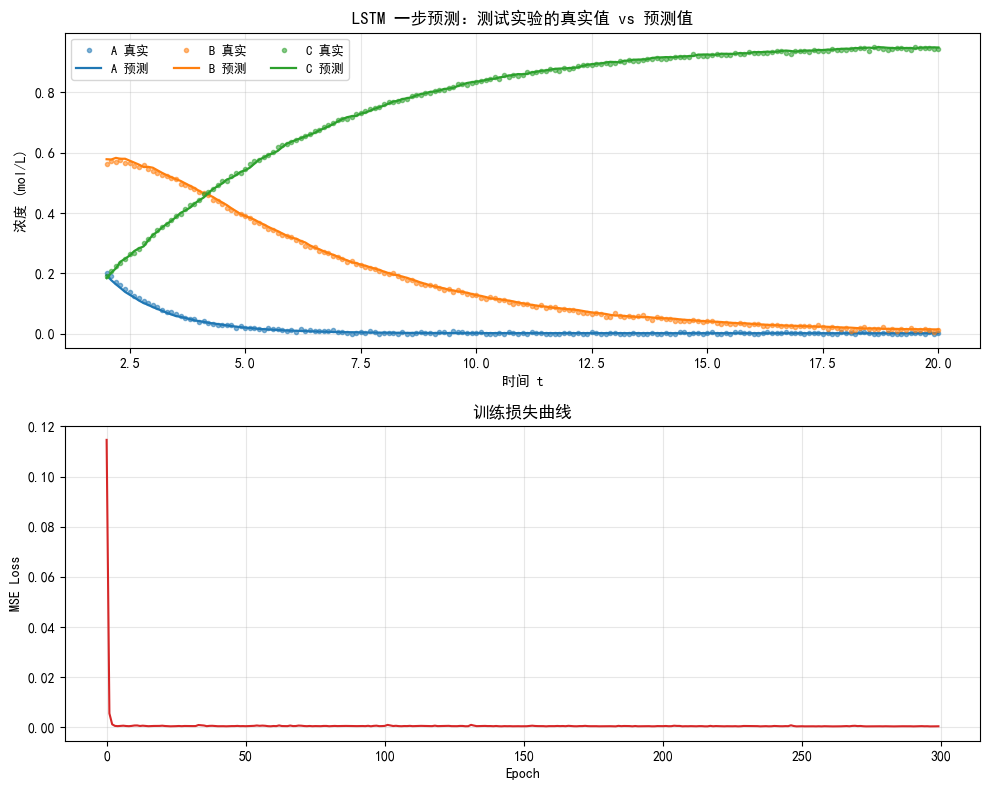

In [8]:
# ===== 6. 可视化 =====
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# ---- 上图：真实值 vs 预测值 ----
ax = axes[0]
t_test = t[SEQ_LEN: SEQ_LEN + len(true_real)]   # 每个样本的预测目标对应的时间点
colors = ["tab:blue", "tab:orange", "tab:green"]
# enumerate 同时拿到下标 j 和物质名；下标 j 用来取第 j 列浓度
for j, name in enumerate(["A", "B", "C"]):
    ax.plot(t_test, true_real[:, j], "o", ms=3, color=colors[j], alpha=0.55, label=f"{name} 真实")
    ax.plot(t_test, pred_real[:, j], "-", lw=1.6, color=colors[j], label=f"{name} 预测")
ax.set_xlabel("时间 t")
ax.set_ylabel("浓度 (mol/L)")
ax.set_title("LSTM 一步预测：测试实验的真实值 vs 预测值")
ax.legend(ncol=3, fontsize=9)
ax.grid(alpha=0.3)

# ---- 下图：训练损失曲线 ----
axes[1].plot(loss_history, color="tab:red")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE Loss")
axes[1].set_title("训练损失曲线")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 7. 小结与思考题

### 小结

1. **数据**：连续一级反应 A→B→C 有解析解，用它生成 6 次带噪声的模拟实验，其中 1 次留作测试；
2. **样本构造**：用长度 20 的滑动窗口，把“历史浓度序列”映射到“下一时刻浓度”，得到 905 个训练样本；
3. **模型**：`nn.LSTM` 读取 20 步序列，取最后一步隐藏状态，经全连接层输出 3 个浓度；
4. **训练**：MSE 损失 + Adam + 梯度裁剪，300 轮后损失稳定；
5. **评估**：LSTM 的 RMSE 低于“保持上一步不变”的基线，说明模型确实学到了浓度变化规律；
6. **实验设计**：按整条轨迹划分数据集、只用训练集统计量做标准化、设置朴素基线——这三点比模型结构本身更影响结论的可信度。

### 思考题

1. 把 `SEQ_LEN` 分别改成 5、10、40，观察测试 RMSE 如何变化，并解释原因（提示：窗口越长，历史信息越多，但训练样本越少）。
2. 把 `noise_sigma` 增大到 0.02，模型还能预测准吗？此时基线的表现如何？
3. 尝试让模型一次预测未来 5 个时间点（`HORIZON=5`，输出维度从 3 改为 15），需要修改哪些代码？
4. 本演示的测试实验参数落在训练实验的参数范围之内（属于插值）。如果把测试实验的速率常数换成范围外的值（例如 k1=1.5），预测会怎样？这说明了机器学习模型什么局限？
5. 为什么标准化只能用训练集的均值和标准差？如果用全部数据（含测试集）计算，会带来什么问题？